# Photoreal real2sim: splats composited into LIBERO

Gaussian splats replace the *appearance* of chosen LIBERO bodies (table, bowl, plate); physics and the robot stay LIBERO's own. The robot mesh and the splats are merged per pixel by depth.

- **Modules:** `hurobo.splat` (`SplatCompositor`, `SplatAsset`, `SplatFit`), `hurobo.sim.LiberoTask`
- **Script version:** `scripts/08_splat_composite.py` (full scripted pick-and-place video)
- **Needs:** a CUDA GPU (gsplat) and EGL; first run may JIT-compile gsplat kernels

The splats here are DISCOVERSE stand-ins, not a scan of our own table, and the motion below is only a teleported bowl, so this shows the *rendering path*, not a policy result.

In [1]:
from hurobo.utils.notebook import setup_notebook

ROOT = setup_notebook()  # chdir to the repo root and set MUJOCO_GL=egl; must precede any mujoco import

In [2]:
%%capture
# (capture hides robosuite's startup logging)
from hurobo.sim import LiberoTask
from hurobo.splat import LIBERO_GOAL_DISTRACTOR_ROOTS, SplatCompositor, build_assets
from hurobo.utils.plotting import plot_image_row

task = LiberoTask("libero_goal", 8)
task.reset()
# build_assets: DISCOVERSE pink bowl, white plate and table cloth (downloaded on first use).
compositor = SplatCompositor(
    task.mj_model,
    build_assets(
        bowl_ply="data/splats/dummy_discoverse/object__bowl_pink.ply"
    ),  # object__bowl_pink.ply | dummy_fruit_bowl.ply | bowl.ply
    hidden_body_roots=LIBERO_GOAL_DISTRACTOR_ROOTS,
    width=384,
    height=384,
)

In [3]:
print(f"{compositor.num_gaussians:,} Gaussians attached")

296,764 Gaussians attached


## The four layers
Native LIBERO, the mesh layer (robot and anything not replaced), the splat layer alone, and the depth composite a policy would see.

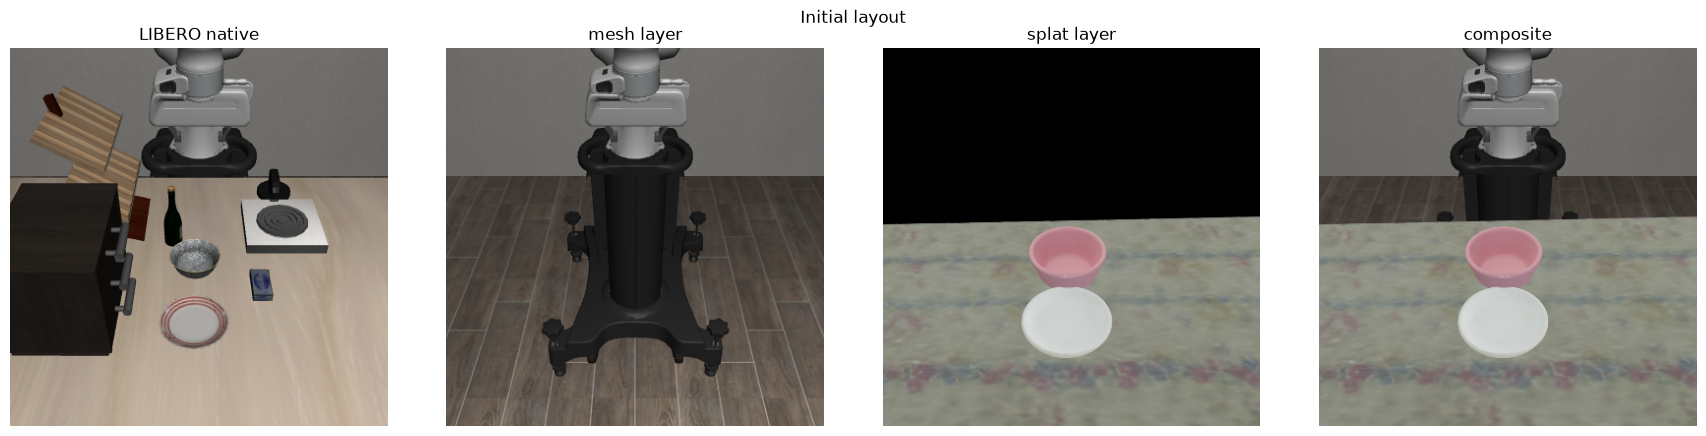

In [4]:
plot_image_row(compositor.render_layers(task.mj_data, "agentview"), "Initial layout")

## Splats follow their bodies
Move the bowl in the simulator; its splat moves with it because it is attached to the body's `xpos`/`xquat` every frame.

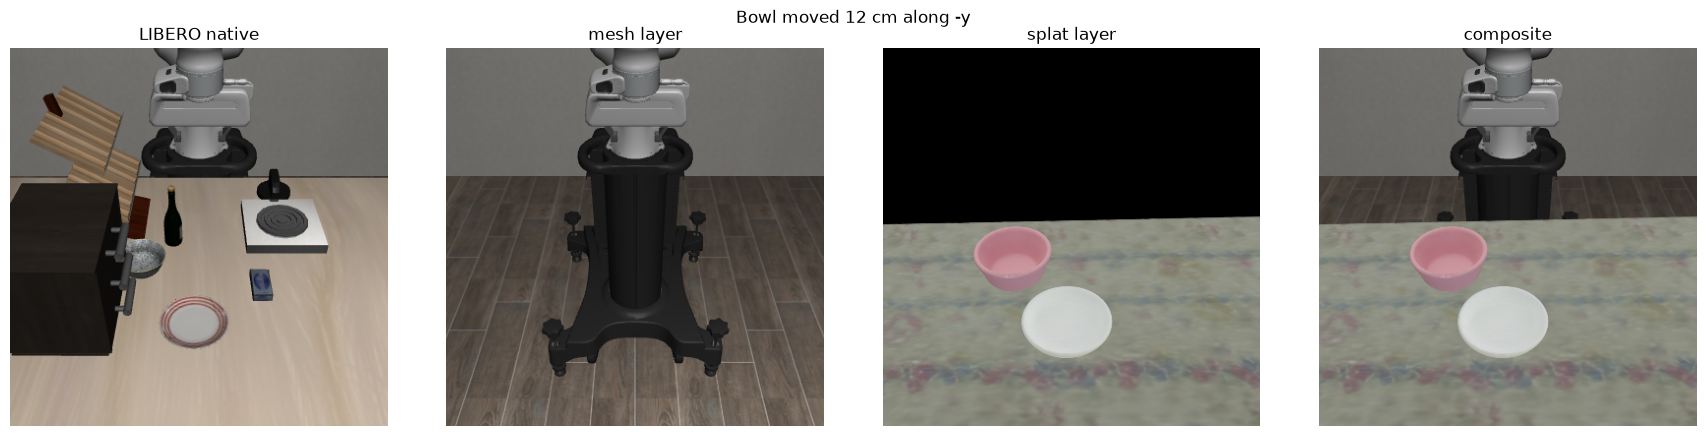

In [5]:
import numpy as np

task.translate_object("akita_black_bowl_1_joint0", np.array([0.0, -0.12, 0.0]))
plot_image_row(compositor.render_layers(task.mj_data, "agentview"), "Bowl moved 12 cm along -y")

# Best scans and DISCOVERSE examples, stock size vs scaled to the real measurements

Four splat sets are attached with `MATCH_BODY_XY`, so a splat takes the size of the body it replaces:

- **DISCOVERSE pink bowl + white plate** and **yellow bowl + green plate**: the stand-ins;
- **best scan**: bowl `bowl_high_low/combined` and plate `plate_med/robust_exhaustive`, and the same with the plate's gaps closed by the shape prior.

Each set is drawn twice. **Stock**: LIBERO's own bodies (its plate is about half the real one). **Scaled**: bodies scaled so the diameters equal `data/raw/setup_01/measurements.yaml` (bowl 13.8 cm, plate 25.5 cm), as in experiment E1. Object positions differ between the two by design: the scaled scene uses our own layout and parks the other objects.

In [6]:
from hurobo.best_scans import BestScans
from hurobo.real_setup import RealSetup
from hurobo.scaled_native import render_unscaled_vs_scaled
from hurobo.splat import DUMMY_SPLAT_DIR, build_assets

best = BestScans()
asset_sets = {
    "DISCOVERSE pink + white": build_assets(),
    "DISCOVERSE yellow + green": build_assets(
        bowl_ply=DUMMY_SPLAT_DIR / "object__yellow_bowl.ply",
        plate_ply=DUMMY_SPLAT_DIR / "object__green_plate.ply",
    ),
    "best scan": build_assets(bowl_ply=best.bowl_ply, plate_ply=best.plate_ply),
    "best scan, filled plate": build_assets(bowl_ply=best.bowl_ply, plate_ply=best.plate_filled_ply),
}
setup = RealSetup.load()
comparison = render_unscaled_vs_scaled(asset_sets, setup, size=320)

Creating LIBERO envs | suites=['libero_goal'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[8]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_goal | task_id=8 | n_envs=1


Creating LIBERO envs | suites=['libero_goal'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[8]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_goal | task_id=8 | n_envs=1


/home/eeschner/alfredo/workspace/hurobo/.venv/lib/python3.12/site-packages/robosuite/utils/binding_utils.py:1010: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  self.qpos[addr] = value


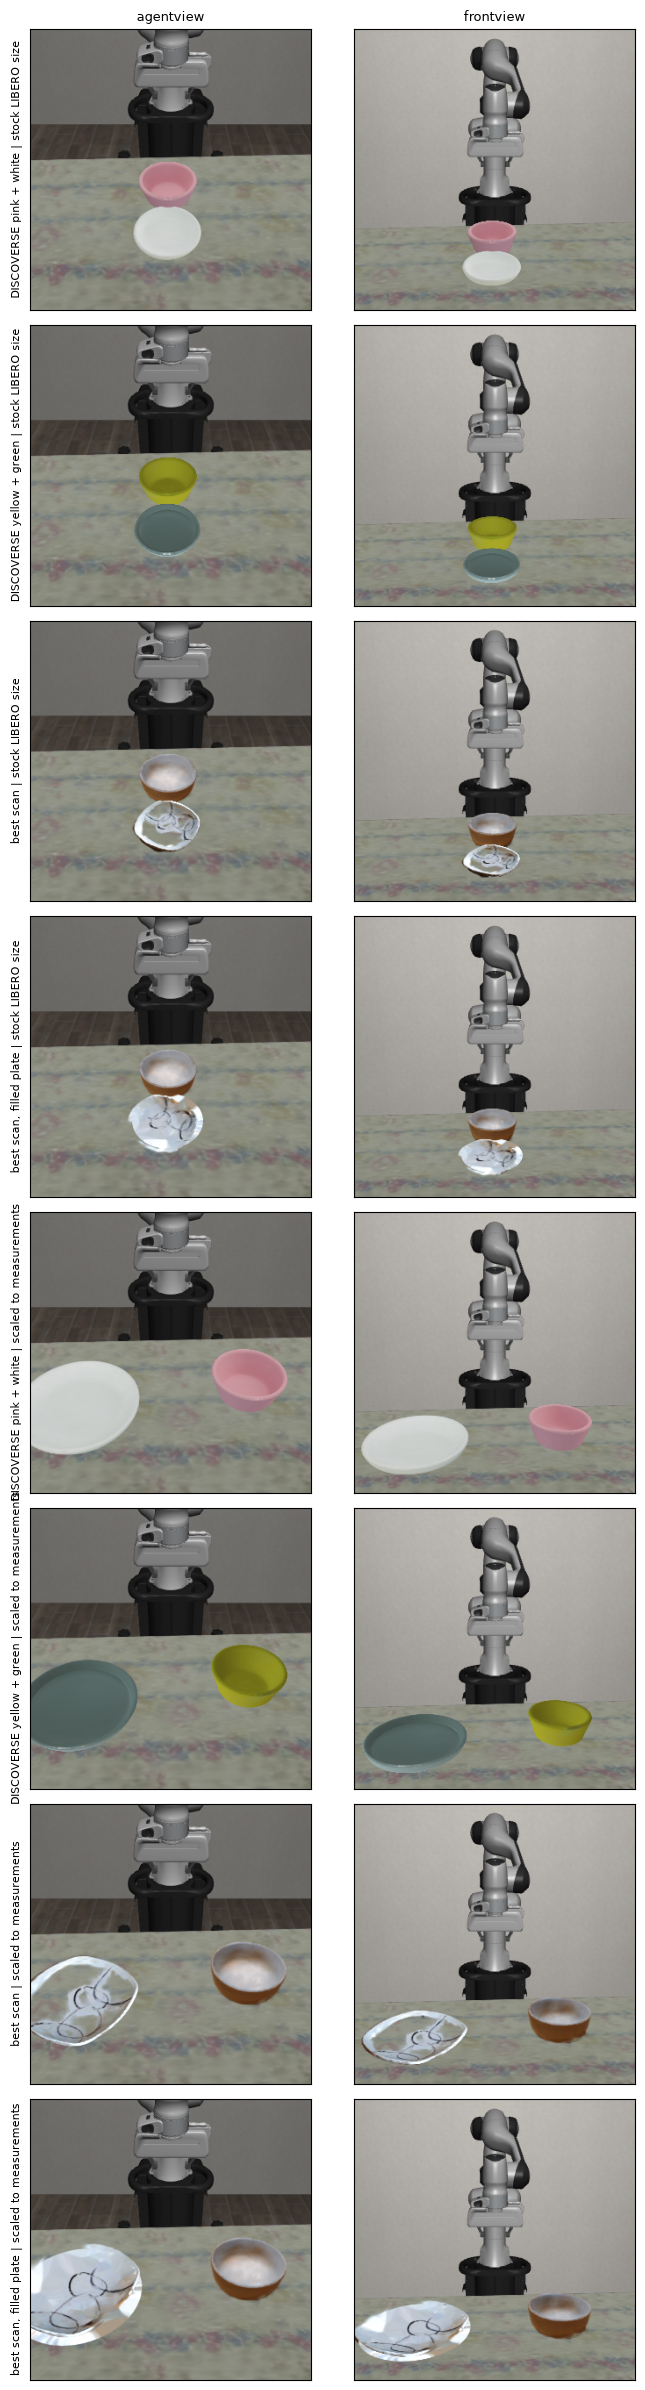

In [7]:
from hurobo.utils.plotting import plot_image_grid

halves = {k: [v[:, : v.shape[1] // 2], v[:, v.shape[1] // 2 :]] for k, v in comparison.items()}
plot_image_grid(halves, column_titles=["agentview", "frontview"], cell_in=3.0)

### Sizes
LIBERO's own diameters against the measured ones and the factor applied. A uniform scale matches the diameter exactly; the height follows from the asset's proportions.

In [8]:
import pandas as pd

from hurobo.scaled_native import ScaledNativeScene

size_scene = ScaledNativeScene(setup)
size_scene.reset()
size_rows = size_scene.scales.comparison(setup)
size_scene.task.close()
pd.DataFrame(size_rows).set_index("object").round(2)

Creating LIBERO envs | suites=['libero_goal'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[8]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_goal | task_id=8 | n_envs=1


,real diameter,LIBERO diameter,scale factor,sim diameter,real height,LIBERO height,sim height
object,,,,,,,
bowl,13.8,11.25,1.23,13.8,6.7,5.26,6.46
plate,25.5,13.75,1.85,25.5,2.8,1.66,3.09


### Reading it
- Stock, the real plate (25.5 cm) is drawn at LIBERO's smaller size, so a scanned plate is shrunk and the bowl sits beside it at almost the same size; scaled, the plate is the large dish it really is next to a 13.8 cm bowl.
- A scan carries its own proportions into the scene: the scanned bowl is flatter than the measured one (see notebook 02, height / diameter), and the filled plate shows facets and a prior-shaped rim. The scaling fixes diameters, not shape.
- The scaled layout is not LIBERO's init state, so compare sizes, not positions.

In [9]:
compositor.close()
task.close()